In [6]:
import pandas as pd

In [7]:
df = pd.read_csv("../Data/raw/eurostat_employment_education.csv")# первая таблица 

## H1. Educación y empleo en Europa

**Hipótesis:** Las personas con un nivel educativo más alto presentan una mayor tasa de empleo. La magnitud de esta relación varía entre los países europeos.

Esta notebook desarrolla la primera de las tres hipótesis del proyecto *Education, Cognitive Skills and Employment in the Age of Artificial Intelligence*. Los resultados se interpretan como asociaciones descriptivas, no como relaciones causales.

In [8]:
df.head()

,STRUCTURE,STRUCTURE_ID,STRUCTURE_NAME,freq,Time frequency,unit,Unit of measure,sex,Sex,age,...,geo,Geopolitical entity (reporting),TIME_PERIOD,Time,OBS_VALUE,Observation value,OBS_FLAG,Observation status (Flag) V2 structure,CONF_STATUS,Confidentiality status (flag)
0,dataflow,ESTAT:LFSA_ERGAED(1.0),Employment rates by educational attainment level,A,Annual,PC,Percentage,F,Females,Y25-64,...,AT,Austria,2015,NaN,49.1,NaN,NaN,NaN,NaN,NaN
1,dataflow,ESTAT:LFSA_ERGAED(1.0),Employment rates by educational attainment level,A,Annual,PC,Percentage,F,Females,Y25-64,...,AT,Austria,2016,NaN,49.9,NaN,NaN,NaN,NaN,NaN
2,dataflow,ESTAT:LFSA_ERGAED(1.0),Employment rates by educational attainment level,A,Annual,PC,Percentage,F,Females,Y25-64,...,AT,Austria,2017,NaN,49.9,NaN,NaN,NaN,NaN,NaN
3,dataflow,ESTAT:LFSA_ERGAED(1.0),Employment rates by educational attainment level,A,Annual,PC,Percentage,F,Females,Y25-64,...,AT,Austria,2018,NaN,50.6,NaN,NaN,NaN,NaN,NaN
4,dataflow,ESTAT:LFSA_ERGAED(1.0),Employment rates by educational attainment level,A,Annual,PC,Percentage,F,Females,Y25-64,...,AT,Austria,2019,NaN,50.5,NaN,NaN,NaN,NaN,NaN


In [9]:
df["TIME_PERIOD"].unique() #gthbjl 2015 - 2025

array([2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025])

## Contexto del proyecto

El proyecto aborda tres dimensiones relacionadas con las perspectivas laborales: educación formal (H1), situación migratoria (H2) y competencias cognitivas (H3). Esta notebook se centra exclusivamente en H1: la relación entre nivel educativo y tasa de empleo en Europa.

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7218 entries, 0 to 7217
Data columns (total 23 columns):
 #   Column                                                           Non-Null Count  Dtype  
---  ------                                                           --------------  -----  
 0   STRUCTURE                                                        7218 non-null   str    
 1   STRUCTURE_ID                                                     7218 non-null   str    
 2   STRUCTURE_NAME                                                   7218 non-null   str    
 3   freq                                                             7218 non-null   str    
 4   Time frequency                                                   7218 non-null   str    
 5   unit                                                             7218 non-null   str    
 6   Unit of measure                                                  7218 non-null   str    
 7   sex                                                  

In [11]:
df.shape

(7218, 23)

In [12]:
df["TIME_PERIOD"].min(), df["TIME_PERIOD"].max() # период

(np.int64(2015), np.int64(2025))

In [13]:
df["geo"].nunique() # кол-во стран

38

In [14]:
df["isced11"].unique() # категории образования: 
# ED0-2: Начальное и основное образование или ниже.
# ED3_4:Среднее образование и послесреднее, не являющееся высшим. 
# ED5-8: Короткий цикл высшего образования, бакалавриат, магистратура, докторантура..

<StringArray>
['ED0-2', 'ED3_4', 'ED5-8']
Length: 3, dtype: str

In [15]:
# Удаляем столбцы, которые полностью пустые
df = df.dropna(axis=1, how="all")

In [16]:

df.shape
# Проверяем обновлённую структуру

(7218, 19)

In [17]:
df[["sex", "age", "isced11", "OBS_VALUE"]].head() 

,sex,age,isced11,OBS_VALUE
0,F,Y25-64,ED0-2,49.1
1,F,Y25-64,ED0-2,49.9
2,F,Y25-64,ED0-2,49.9
3,F,Y25-64,ED0-2,50.6
4,F,Y25-64,ED0-2,50.5


## H1. Educación y empleo en Europa

### Fuente de datos
- Organismo: Eurostat
- Dataset: lfsa_ergaed
- Archivo: eurostat_employment_education.csv
- Periodo analizado: 2015–2025
- Cobertura geográfica: 38 países/territorios
- Número de registros iniciales: 7.218
- Número de columnas iniciales: 23

### Hipótesis
Las personas con un nivel educativo más alto presentan una mayor tasa de empleo. La magnitud de esta relación varía entre los países europeos.

### Variables principales
| Variable | Descripción |
|---|---|
| geo | País o territorio |
| TIME_PERIOD | Año de observación |
| isced11 | Nivel educativo (clasificación ISCED 2011) |
| sex | Sexo |
| age | Grupo de edad |
| OBS_VALUE | Tasa de empleo (%) |

### Categorías educativas
- ED0-2: Educación baja (ISCED 0–2)
- ED3_4: Educación media (ISCED 3–4)
- ED5-8: Educación alta (ISCED 5–8)

### Análisis previsto
Comparar las tasas de empleo por nivel educativo, país y año.

In [18]:
df["sex"].unique(), df["age"].unique()

(<StringArray>
 ['F', 'M', 'T']
 Length: 3, dtype: str,
 <StringArray>
 ['Y25-64', 'Y25-74']
 Length: 2, dtype: str)

In [19]:
df["geo"].unique()

<StringArray>
[       'AT',        'BA',        'BE',        'BG',        'CH',        'CY',
        'CZ',        'DE',        'DK',      'EA21',        'EE',        'EL',
        'ES', 'EU27_2020',        'FI',        'FR',        'HR',        'HU',
        'IE',        'IS',        'IT',        'LT',        'LU',        'LV',
        'ME',        'MK',        'MT',        'NL',        'NO',        'PL',
        'PT',        'RO',        'RS',        'SE',        'SI',        'SK',
        'TR',        'UK']
Length: 38, dtype: str

In [20]:
df["age"].unique()

<StringArray>
['Y25-64', 'Y25-74']
Length: 2, dtype: str

In [21]:
df = df[df["age"] == "Y25-64"]# оставляем только возрастную группу 25-64

In [22]:
df["sex"].unique()

<StringArray>
['F', 'M', 'T']
Length: 3, dtype: str

In [23]:
df = df[df["sex"] == "T"] # оставляем только общий показатель по полу

In [24]:
df.shape

(1203, 19)

In [25]:
df["isced11"].unique()

<StringArray>
['ED0-2', 'ED3_4', 'ED5-8']
Length: 3, dtype: str

In [26]:
df["geo"].unique()

<StringArray>
[       'AT',        'BA',        'BE',        'BG',        'CH',        'CY',
        'CZ',        'DE',        'DK',      'EA21',        'EE',        'EL',
        'ES', 'EU27_2020',        'FI',        'FR',        'HR',        'HU',
        'IE',        'IS',        'IT',        'LT',        'LU',        'LV',
        'ME',        'MK',        'MT',        'NL',        'NO',        'PL',
        'PT',        'RO',        'RS',        'SE',        'SI',        'SK',
        'TR',        'UK']
Length: 38, dtype: str

In [27]:
df = df[~df["geo"].isin(["EU27_2020", "EA21"])]

In [28]:
df.shape

(1137, 19)

In [29]:
df["TIME_PERIOD"].unique()

array([2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025])

In [30]:
df.columns

Index(['STRUCTURE', 'STRUCTURE_ID', 'STRUCTURE_NAME', 'freq', 'Time frequency',
       'unit', 'Unit of measure', 'sex', 'Sex', 'age', 'Age class', 'isced11',
       'International Standard Classification of Education (ISCED 2011)',
       'geo', 'Geopolitical entity (reporting)', 'TIME_PERIOD', 'OBS_VALUE',
       'OBS_FLAG', 'Observation status (Flag) V2 structure'],
      dtype='str')

H1 ключевые столбцы:
- geo — страна
- TIME_PERIOD — год
- isced11 — уровень образования
- OBS_VALUE — показатель занятости
- sex — пол
- age — возрастная группа

In [31]:
df["unit"].unique()

<StringArray>
['PC']
Length: 1, dtype: str

In [32]:
df["OBS_VALUE"].describe()

count    1137.000000
mean       72.200352
std        15.066978
min        24.200000
25%        61.100000
50%        75.300000
75%        85.100000
max        93.600000
Name: OBS_VALUE, dtype: float64

In [33]:
df.isnull().sum()

STRUCTURE                                                            0
STRUCTURE_ID                                                         0
STRUCTURE_NAME                                                       0
freq                                                                 0
Time frequency                                                       0
unit                                                                 0
Unit of measure                                                      0
sex                                                                  0
Sex                                                                  0
age                                                                  0
Age class                                                            0
isced11                                                              0
International Standard Classification of Education (ISCED 2011)      0
geo                                                                  0
Geopol

In [34]:
df["OBS_FLAG"].value_counts(dropna=False)

OBS_FLAG
NaN    963
b      144
d       21
bd       9
Name: count, dtype: int64

In [35]:
df.duplicated(subset=["geo", "TIME_PERIOD", "isced11"]).sum() # функция для проверки дубликатов по столбцам geo, TIME_PERIOD и isced11

np.int64(0)

In [36]:
df.groupby("isced11")["OBS_VALUE"].mean().round(2) #первый показатель среднего значения по категориям образования 

isced11
ED0-2    54.85
ED3_4    75.70
ED5-8    86.05
Name: OBS_VALUE, dtype: float64

Первое наблюдение для H1: в нашем наборе данных страны с более высоким уровнем образования демонстрируют более высокий средний уровень занятости.
Разница между низким и высоким уровнем образования составляет 31,20 процентного пункта. Это пока описательный результат, а не доказательство причинно-следственной связи.

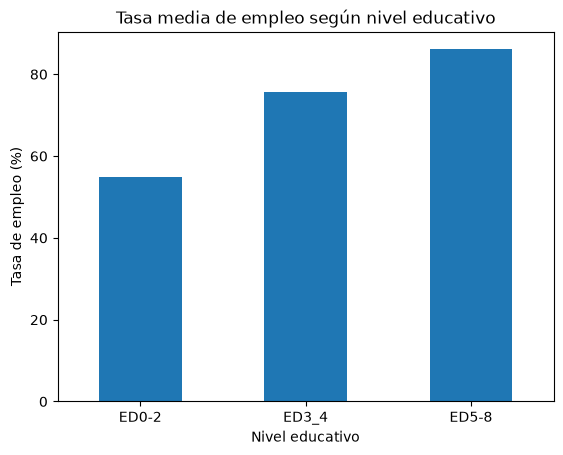

In [37]:
import matplotlib.pyplot as plt

empleo_educacion = df.groupby("isced11")["OBS_VALUE"].mean()

empleo_educacion.plot(kind="bar")

plt.title("Tasa media de empleo según nivel educativo")
plt.xlabel("Nivel educativo")
plt.ylabel("Tasa de empleo (%)")
plt.xticks(rotation=0)
plt.show()

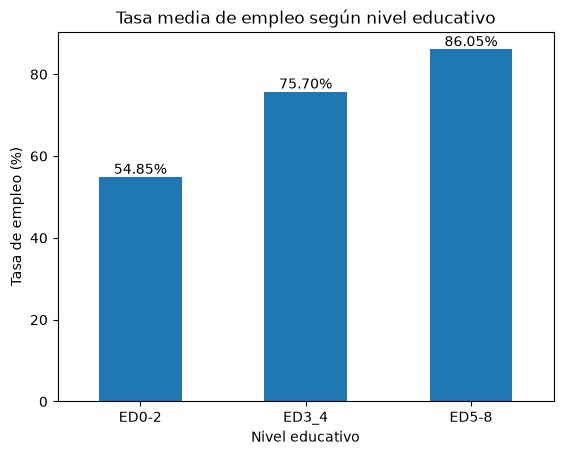

In [38]:
import matplotlib.pyplot as plt

empleo_educacion = df.groupby("isced11")["OBS_VALUE"].mean()

ax = empleo_educacion.plot(kind="bar")

plt.title("Tasa media de empleo según nivel educativo")
plt.xlabel("Nivel educativo")
plt.ylabel("Tasa de empleo (%)")
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.show()

График выше наглядно показывает результат H1: чем выше уровень образования, тем выше средний уровень занятости.

In [39]:
empleo_anual = df.groupby(["TIME_PERIOD", "isced11"])["OBS_VALUE"].mean().unstack() # средний уровень занятости по каждому году отдельно для трёх уровней образования

empleo_anual

isced11,ED0-2,ED3_4,ED5-8
TIME_PERIOD,,,
2015,51.765714,72.562857,83.580000
2016,52.711429,73.314286,84.165714
2017,53.982857,74.588571,84.885714
2018,55.088571,75.617143,85.468571
2019,55.717143,76.131429,85.977143
2020,54.467647,74.805882,85.176471
2021,54.055882,75.364706,86.258824
2022,55.667647,77.082353,87.385294
2023,56.658824,77.438235,87.664706


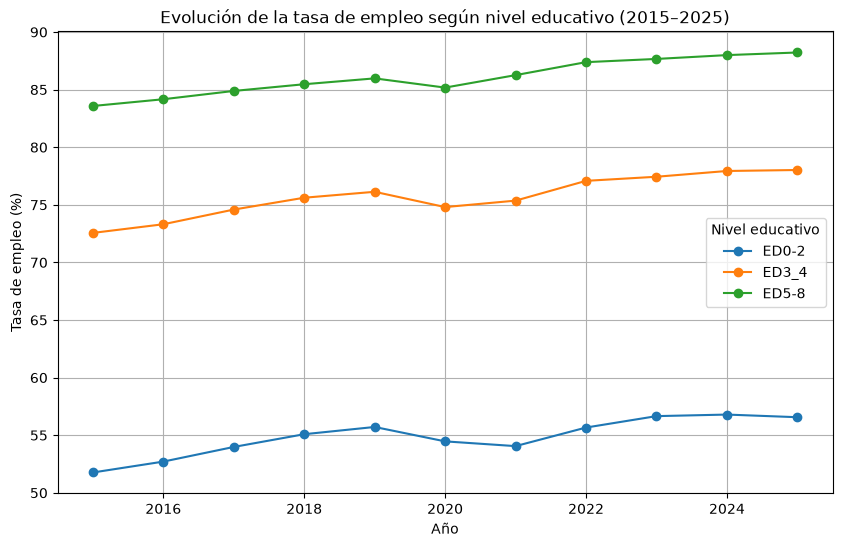

In [40]:
# Рисуем график с линиями для каждого уровня образования по годам

empleo_anual.plot(kind="line", marker="o", figsize=(10, 6))

plt.title("Evolución de la tasa de empleo según nivel educativo (2015–2025)")
plt.xlabel("Año")
plt.ylabel("Tasa de empleo (%)")
plt.legend(title="Nivel educativo")
plt.grid(True)
plt.show()

In [41]:
brecha_educativa = empleo_anual["ED5-8"] - empleo_anual["ED0-2"]

brecha_educativa.round(2)

TIME_PERIOD
2015    31.81
2016    31.45
2017    30.90
2018    30.38
2019    30.26
2020    30.71
2021    32.20
2022    31.72
2023    31.01
2024    31.20
2025    31.66
dtype: float64

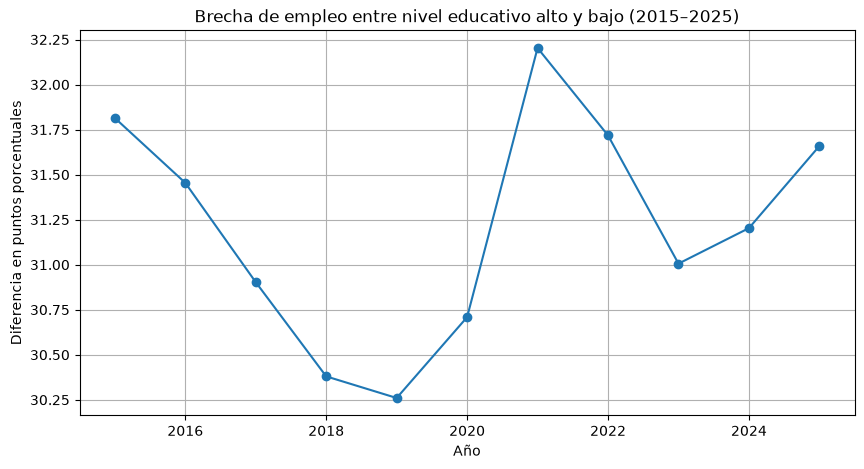

In [42]:
brecha_educativa.plot(kind="line", marker="o", figsize=(10, 5))

plt.title("Brecha de empleo entre nivel educativo alto y bajo (2015–2025)")
plt.xlabel("Año")
plt.ylabel("Diferencia en puntos porcentuales")
plt.grid(True)
plt.show()

«La pandemia de COVID-19 podría haber influido en la evolución de la brecha de empleo entre los distintos niveles educativos, especialmente durante 2020 y 2021. Esta relación requiere un análisis más profundo.»

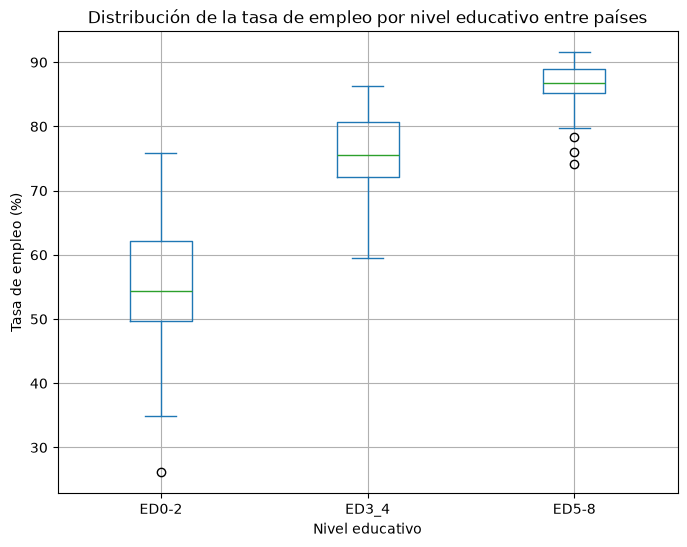

In [43]:
empleo_pais = df.groupby(["geo", "isced11"])["OBS_VALUE"].mean().unstack()

empleo_pais[["ED0-2", "ED3_4", "ED5-8"]].plot(
    kind="box",
    figsize=(8, 6)
)

plt.title("Distribución de la tasa de empleo por nivel educativo entre países")
plt.xlabel("Nivel educativo")
plt.ylabel("Tasa de empleo (%)")
plt.grid(True)
plt.show()

In [44]:
empleo_pais.idxmin()

isced11
ED0-2    BA
ED3_4    ME
ED5-8    TR
dtype: str

In [45]:
empleo_pais.idxmax()

isced11
ED0-2    IS
ED3_4    IS
ED5-8    IS
dtype: str

In [46]:
empleo_pais.loc[["BA", "ME", "TR", "IS"]].round(2) #

isced11,ED0-2,ED3_4,ED5-8
geo,,,
BA,26.10,61.90,81.14
ME,34.97,59.43,78.33
TR,48.14,61.49,74.21
IS,75.83,86.27,91.52


Наблюдение: Исландия показывает самые высокие средние значения занятости во всех образовательных группах. В Боснии и Герцеговине особенно низкая занятость среди людей с низким уровнем образования — 26,10%.

Это подчёркивает, что различия связаны не только с уровнем образования, но и с контекстом конкретной страны.

In [47]:
brecha_pais = empleo_pais["ED5-8"] - empleo_pais["ED0-2"]

brecha_pais.sort_values(ascending=False).round(2)

geo
BA    55.04
SK    50.15
HR    46.18
PL    43.73
ME    43.37
MK    42.56
BG    41.15
LT    40.18
RO    39.59
BE    39.52
SI    37.89
IE    32.85
FR    32.45
FI    32.35
CZ    32.22
AT    31.32
HU    31.01
RS    30.48
IT    29.31
NO    28.30
LV    28.18
SE    27.34
MT    26.37
DE    26.35
DK    26.16
TR    26.07
LU    25.55
NL    24.75
ES    23.80
EL    23.02
UK    22.24
EE    21.99
CH    20.91
CY    19.63
PT    19.37
IS    15.69
dtype: float64

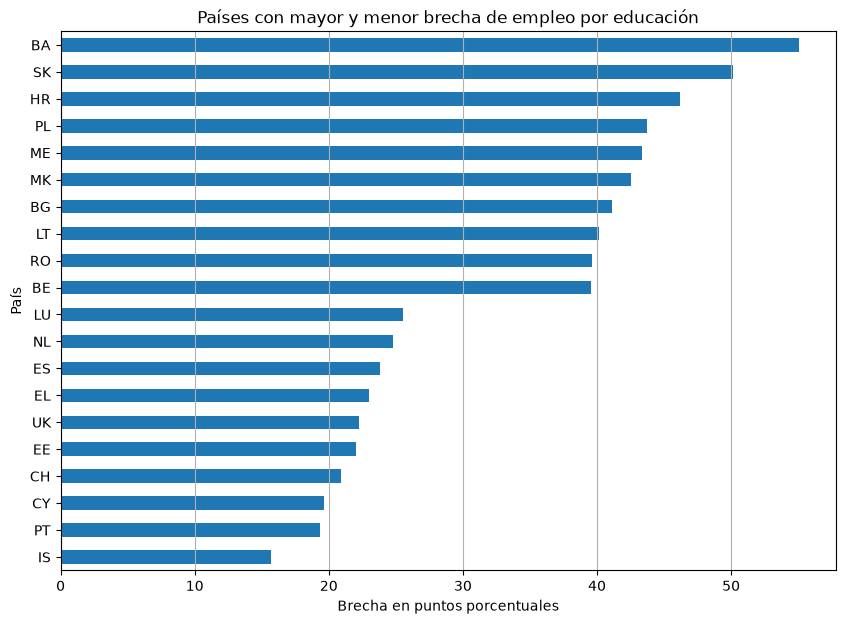

In [48]:
brecha_extremos = pd.concat([
    brecha_pais.sort_values(ascending=False).head(10),
    brecha_pais.sort_values().head(10)
]).sort_values()

brecha_extremos.plot(kind="barh", figsize=(10, 7))

plt.title("Países con mayor y menor brecha de empleo por educación")
plt.xlabel("Brecha en puntos porcentuales")
plt.ylabel("País")
plt.grid(axis="x")
plt.show()

Он наглядно показывает, что разрыв в уровне занятости между людьми с высоким и низким образованием существенно отличается в разных странах.

### Conclusión H1

Los resultados del análisis exploratorio confirman la hipótesis H1. Se observa una relación positiva entre el nivel educativo y la tasa de empleo: cuanto mayor es el nivel educativo, mayor es la tasa media de empleo.

La tasa media de empleo es del 54,85% para las personas con bajo nivel educativo, del 75,70% para el nivel medio y del 86,05% para el nivel alto.

Además, la brecha entre los niveles educativos varía considerablemente entre países, siendo más elevada en Bosnia y Herzegovina (BA) y más reducida en Islandia (IS).

Estos resultados muestran una asociación entre educación y empleo, aunque no permiten establecer una relación causal.

In [49]:
df["sex"].unique()

<StringArray>
['T']
Length: 1, dtype: str